# Plant Growth Before and After Compost
**Mini Project: Paired t-test using Python**

Name: NUKALA JASHWANT SAI
PRN: B25CE1177
Libraries: NumPy, SciPy (`scipy.stats`), Matplotlib (`pyplot`)

**Note:** The data in this project is simulated. I did not have real plant measurements, so I made up 10 realistic values to show how the paired t-test works. The results only describe this sample data and say nothing about real plants.

## 1. Aim

People say that adding compost helps plants grow taller. To check an idea like this, we can measure the same plants before and after adding compost and see if the average height changed.

Since each plant is measured two times, the two sets of values are paired, so a paired t-test is the right test here. It works on the difference for each plant.

What this notebook does:
1. Creates a simulated dataset of 10 plants (height before and after compost).
2. Finds the mean, sample standard deviation (`ddof=1`) and the growth of each plant.
3. Does a two-tailed paired t-test at the 5% significance level.
4. Draws three graphs: a histogram, a box plot and a paired comparison chart.
5. Explains the result and its limits.

## 2. Hypotheses and Method

Let d = After - Before be the growth of a plant in cm, and let mu_d be the true mean growth.

- H0 (null): mu_d = 0, so compost makes no difference to the mean height.
- H1 (alternative): mu_d is not equal to 0, so the mean height is different after compost (two-tailed).
- Significance level: alpha = 0.05

Formulas used:

$$\bar{d}=\frac{\sum d_i}{n}\qquad s_d=\sqrt{\frac{\sum (d_i-\bar{d})^2}{n-1}}\qquad t=\frac{\bar{d}}{s_d/\sqrt{n}}\qquad df=n-1$$

Decision rule: reject H0 if p-value < 0.05 (same as |t| > critical t).

The test assumes the differences are roughly normal, which is checked in Section 6.

## 3. Importing Libraries

In [1]:
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

# just some basic plot settings
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("NumPy      :", np.__version__)
print("SciPy      :", __import__("scipy").__version__)
print("Matplotlib :", __import__("matplotlib").__version__)

NumPy      : 2.4.4
SciPy      : 1.17.1
Matplotlib : 3.10.8


## 4. Dataset (Simulated)

Heights are in cm. These values are made up for this demonstration and are typed in directly instead of using a random generator, so the output is the same every time the notebook is run.

In [2]:
# NOTE: simulated data, not real measurements
n_plants = 10

plant_ids = np.arange(1, n_plants + 1)

# height of each plant (cm) before compost
before = np.array([12.5, 14.0, 11.8, 13.2, 15.1, 12.9, 13.6, 14.4, 11.5, 13.9])

# height of the same plants (cm) after compost
after  = np.array([15.8, 17.1, 14.2, 16.9, 18.0, 15.4, 16.1, 18.3, 14.6, 16.5])

# growth = after - before
growth = after - before

# print the data as a table
print("SIMULATED DATASET: Plant height (cm)")
print("-" * 46)
print(f"{'Plant':<8}{'Before':>10}{'After':>10}{'Growth':>12}")
print("-" * 46)
for i, b, a, g in zip(plant_ids, before, after, growth):
    print(f"{i:<8}{b:>10.1f}{a:>10.1f}{g:>12.1f}")
print("-" * 46)

SIMULATED DATASET: Plant height (cm)
----------------------------------------------
Plant       Before     After      Growth
----------------------------------------------
1             12.5      15.8         3.3
2             14.0      17.1         3.1
3             11.8      14.2         2.4
4             13.2      16.9         3.7
5             15.1      18.0         2.9
6             12.9      15.4         2.5
7             13.6      16.1         2.5
8             14.4      18.3         3.9
9             11.5      14.6         3.1
10            13.9      16.5         2.6
----------------------------------------------


## 5. Descriptive Statistics

The sample standard deviation is used (`ddof=1`, divides by n - 1) because these 10 plants are treated as a sample.

In [3]:
# mean and sample standard deviation of before and after heights
mean_before, sd_before = before.mean(), before.std(ddof=1)
mean_after,  sd_after  = after.mean(),  after.std(ddof=1)

# mean and sample standard deviation of growth
mean_growth, sd_growth = growth.mean(), growth.std(ddof=1)

print(f"Before compost : mean = {mean_before:.2f} cm,  sample SD = {sd_before:.2f} cm")
print(f"After  compost : mean = {mean_after:.2f} cm,  sample SD = {sd_after:.2f} cm")
print()
print("Individual growth (cm):", np.round(growth, 1))
print(f"Average growth : {mean_growth:.2f} cm")
print(f"SD of growth   : {sd_growth:.2f} cm")
print(f"Smallest / largest growth: {growth.min():.1f} cm / {growth.max():.1f} cm")

Before compost : mean = 13.29 cm,  sample SD = 1.14 cm
After  compost : mean = 16.29 cm,  sample SD = 1.35 cm

Individual growth (cm): [3.3 3.1 2.4 3.7 2.9 2.5 2.5 3.9 3.1 2.6]
Average growth : 3.00 cm
SD of growth   : 0.52 cm
Smallest / largest growth: 2.4 cm / 3.9 cm


## 6. Checking Normality

The paired t-test assumes the differences are roughly normal. With only 10 values this check is not very strong, but it is still worth doing. I used the Shapiro-Wilk test, where H0 says the differences come from a normal distribution.

In [4]:
shapiro_stat, shapiro_p = stats.shapiro(growth)
print(f"Shapiro-Wilk statistic = {shapiro_stat:.4f},  p-value = {shapiro_p:.4f}")

if shapiro_p > 0.05:
    print("p > 0.05 -> no evidence against normality; the t-test assumption is reasonable.")
else:
    print("p <= 0.05 -> differences may not be normal; interpret the t-test with caution.")

Shapiro-Wilk statistic = 0.9175,  p-value = 0.3366
p > 0.05 -> no evidence against normality; the t-test assumption is reasonable.


## 7. Paired t-test (two-tailed, alpha = 0.05)

First the t-test is calculated by hand using the formula, and then it is checked with `scipy.stats.ttest_rel`. Both should give the same answer.

In [5]:
alpha = 0.05

# manual calculation
n  = len(growth)                       # number of pairs
df = n - 1                             # degrees of freedom
se = sd_growth / np.sqrt(n)            # standard error
t_manual = mean_growth / se            # t = d_bar / (s_d / sqrt(n))
p_manual = 2 * stats.t.sf(abs(t_manual), df)   # two-tailed p-value
t_critical = stats.t.ppf(1 - alpha / 2, df)    # critical value

# same test using scipy (two-sided by default)
t_stat, p_value = stats.ttest_rel(after, before)

# 95% confidence interval for the mean growth
ci_low  = mean_growth - t_critical * se
ci_high = mean_growth + t_critical * se

# effect size for paired data (Cohen's d_z)
cohen_dz = mean_growth / sd_growth

print("H0: mean growth = 0      H1: mean growth != 0   (two-tailed, alpha = 0.05)")
print("-" * 62)
print(f"Number of pairs (n)        : {n}")
print(f"Degrees of freedom (n - 1) : {df}")
print(f"Standard error             : {se:.4f}")
print(f"t-statistic (manual)       : {t_manual:.4f}")
print(f"t-statistic (SciPy)        : {t_stat:.4f}")
print(f"p-value (manual)           : {p_manual:.3e}")
print(f"p-value (SciPy)            : {p_value:.3e}")
print(f"Critical t (+/-)           : {t_critical:.4f}")
print(f"95% CI for mean growth     : [{ci_low:.2f}, {ci_high:.2f}] cm")
print(f"Effect size (Cohen's d_z)  : {cohen_dz:.2f}")
print("-" * 62)

# check that manual and scipy results match
assert np.isclose(t_manual, t_stat) and np.isclose(p_manual, p_value)

# decision
if p_value < alpha:
    print(f"DECISION: p = {p_value:.3e} < {alpha}  ->  REJECT H0")
    print("The mean height after compost differs significantly from before (in this simulated data).")
else:
    print(f"DECISION: p = {p_value:.3f} >= {alpha}  ->  FAIL TO REJECT H0")
    print("No significant difference in mean height was found.")

H0: mean growth = 0      H1: mean growth != 0   (two-tailed, alpha = 0.05)
--------------------------------------------------------------
Number of pairs (n)        : 10
Degrees of freedom (n - 1) : 9
Standard error             : 0.1647
t-statistic (manual)       : 18.2200
t-statistic (SciPy)        : 18.2200
p-value (manual)           : 2.063e-08
p-value (SciPy)            : 2.063e-08
Critical t (+/-)           : 2.2622
95% CI for mean growth     : [2.63, 3.37] cm
Effect size (Cohen's d_z)  : 5.76
--------------------------------------------------------------
DECISION: p = 2.063e-08 < 0.05  ->  REJECT H0
The mean height after compost differs significantly from before (in this simulated data).


## 8. Graphs

### 8.1 Histogram of Growth Differences

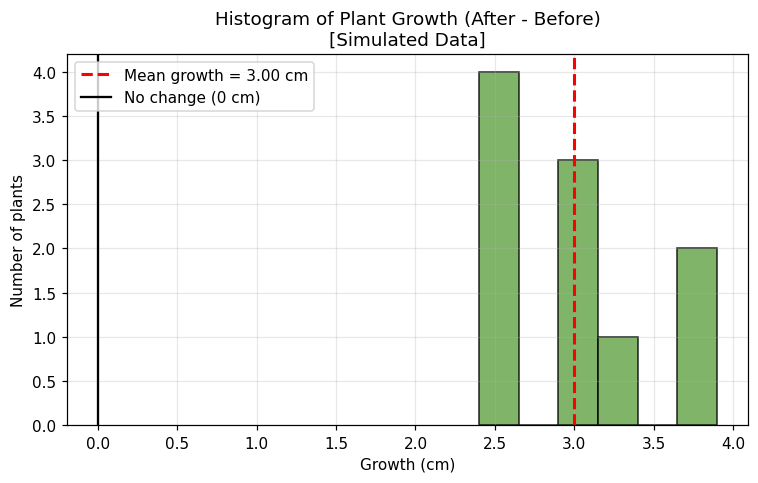

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(growth, bins=6, color="#6aa84f", edgecolor="black", alpha=0.85)
ax.axvline(mean_growth, color="red", linestyle="--", linewidth=2,
           label=f"Mean growth = {mean_growth:.2f} cm")
ax.axvline(0, color="black", linewidth=1.5, label="No change (0 cm)")
ax.set_title("Histogram of Plant Growth (After - Before)\n[Simulated Data]")
ax.set_xlabel("Growth (cm)")
ax.set_ylabel("Number of plants")
ax.legend()
plt.tight_layout()
plt.show()

All growth values are positive and close to the mean, so none of the plants got shorter in this data.

### 8.2 Box Plot: Before vs After

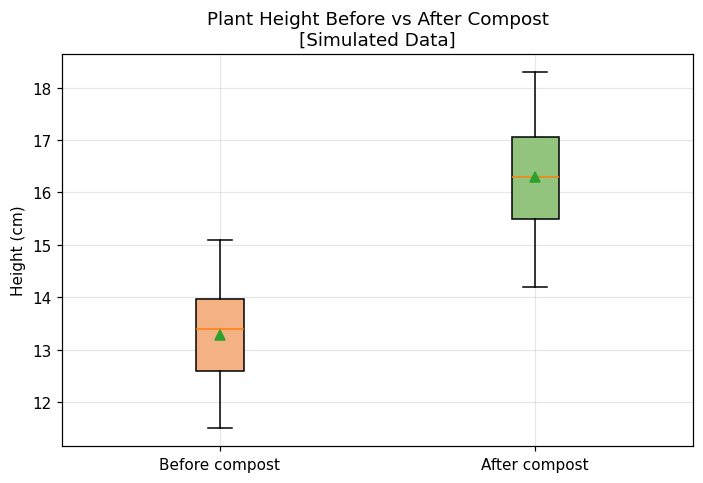

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
bp = ax.boxplot([before, after], tick_labels=["Before compost", "After compost"],
                patch_artist=True, showmeans=True)
for patch, colour in zip(bp["boxes"], ["#f4b183", "#93c47d"]):
    patch.set_facecolor(colour)
ax.set_title("Plant Height Before vs After Compost\n[Simulated Data]")
ax.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()

The 'after' box is higher than the 'before' box (green triangles are the means). The spread of both groups looks similar.

### 8.3 Paired Before-and-After Chart

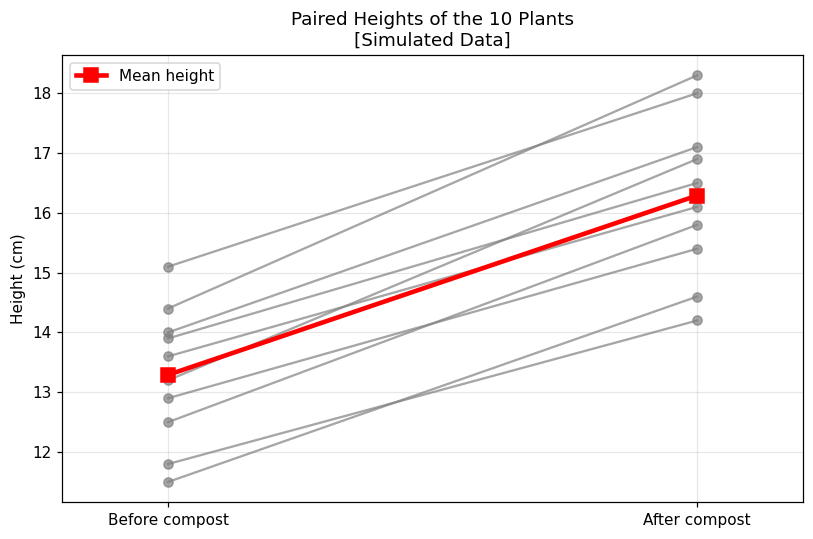

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))

# one line for each plant, joining its before and after height
for b, a in zip(before, after):
    ax.plot([0, 1], [b, a], marker="o", color="gray", alpha=0.7)

# thick red line for the means
ax.plot([0, 1], [mean_before, mean_after], marker="s", color="red",
        linewidth=3, markersize=9, label="Mean height")

ax.set_xticks([0, 1])
ax.set_xticklabels(["Before compost", "After compost"])
ax.set_xlim(-0.2, 1.2)
ax.set_ylabel("Height (cm)")
ax.set_title("Paired Heights of the 10 Plants\n[Simulated Data]")
ax.legend()
plt.tight_layout()
plt.show()

All 10 lines go upwards, so every plant is taller after compost in this data. This is the benefit of using paired data.

## 9. Summary of Results

In [9]:
print("=" * 60)
print("RESULTS SUMMARY  (SIMULATED DATA)")
print("=" * 60)
print(f"Mean height before compost : {mean_before:.2f} cm (SD {sd_before:.2f})")
print(f"Mean height after compost  : {mean_after:.2f} cm (SD {sd_after:.2f})")
print(f"Average growth             : {mean_growth:.2f} cm (SD {sd_growth:.2f})")
print(f"95% CI for mean growth     : [{ci_low:.2f}, {ci_high:.2f}] cm")
print(f"t({df}) = {t_stat:.2f},  p = {p_value:.3e},  Cohen's d_z = {cohen_dz:.2f}")
print("Decision (alpha = 0.05)    :", "Reject H0" if p_value < alpha else "Fail to reject H0")
print("=" * 60)

RESULTS SUMMARY  (SIMULATED DATA)
Mean height before compost : 13.29 cm (SD 1.14)
Mean height after compost  : 16.29 cm (SD 1.35)
Average growth             : 3.00 cm (SD 0.52)
95% CI for mean growth     : [2.63, 3.37] cm
t(9) = 18.22,  p = 2.063e-08,  Cohen's d_z = 5.76
Decision (alpha = 0.05)    : Reject H0


## 10. Interpretation

For the simulated data of 10 plants:

- The mean height increased from 13.29 cm (SD 1.14) before compost to 16.29 cm (SD 1.35) after compost. The average growth is 3.00 cm (SD 0.52).
- The paired t-test gave t(9) = 18.22 and p = 2.06e-08. Since p < 0.05 and |t| is more than the critical value 2.262, we reject H0.
- The 95% confidence interval for the mean growth is [2.63, 3.37] cm, which does not contain 0.
- Cohen's d_z is about 5.76, which is a very large effect. This is because the growth values I made up are very close to each other.

So, in this simulated sample, the mean height after compost is significantly different from (and higher than) the height before compost.

**Limitations**
1. The data is simulated. The strong result comes from how the numbers were written, not from real plants. This project only demonstrates the method.
2. A significant result does not prove that compost caused the growth. There is no control group (plants without compost), so even with real data, things like normal growth over time, watering, weather or sunlight could also explain the increase.
3. 10 plants is a small sample, and the normality check is not very powerful for such a small sample.
4. A real study would need real measurements, a control group, and the same conditions for all plants.

## 11. Conclusion

In this mini project a two-tailed paired t-test was done in Python using NumPy, SciPy and Matplotlib. For the simulated data, the null hypothesis of zero mean growth was rejected at the 5% level. This conclusion is only for the made-up data. Real measurements and a control group would be needed to say anything about the effect of compost on real plants.

## 12. References
- SciPy, `scipy.stats.ttest_rel`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_rel.html
- SciPy, `scipy.stats.shapiro`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html
- NumPy, `numpy.std`: https://numpy.org/doc/stable/reference/generated/numpy.std.html
- Matplotlib, `pyplot.boxplot`: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.boxplot.html
- Wikipedia, Student's t-test: https://en.wikipedia.org/wiki/Student%27s_t-test